# Full Pipeline on the Quasar 3C 273

This notebook applies the pipeline of `full_star_tutorial.ipynb` to a quasar (up to the 18 of Nov). The shared data structures (`Spectrum`, `Line`, `Absorber`) are explained in section 1 of that tutorial and are not repeated here: we focus on what changes from an SDSS star to an HST/COS quasar.

We will study 3C 273, the brightest quasar in the sky, at $z = 0.158$. On its way to us its ultraviolet light crosses:

- the interstellar medium and the halo of the Milky Way: metal lines (Si II, S II, N I, C II, ...) at $v \approx 0$, and the damped Galactic $\mathrm{Ly}\alpha$ at 1216 Å;
- the Virgo cluster, in front of which 3C 273 lies: $\mathrm{Ly}\alpha$ at $cz \approx 1000-1600$ km/s;
- the low-redshift intergalactic medium: the $\mathrm{Ly}\alpha$ forest, from 1216 Å ($z = 0$) up to the $\mathrm{Ly}\alpha$ emission of the quasar itself, at $1216 \times 1.158 \approx 1408$ Å.

In [44]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt

## 1. Downloading and reading the quasar

3C 273 has no SDSS spectrum. Its ultraviolet spectrum comes from the Cosmic Origins Spectrograph (COS) on HST. Besides the target, `query_mast` (`spectral_diag/mast_archive.py`) accepts any filter of astroquery's `Observations.query_criteria`; here we keep the COS far-UV (FUV) observations. All of them use the G130M grating, which covers about 1130–1460 Å at a resolving power $R \approx 19\,000$.

In [45]:
from spectral_diag.mast_archive import query_mast

obs = query_mast("3C 273", obs_collection="HST", instrument_name="COS/FUV")
obs["obs_id", "filters", "t_exptime", "proposal_id"]

obs_id,filters,t_exptime,proposal_id
str9,str5,float64,str5
lbgl31020,G130M,1192.192,12038
lbgl31rhq,G130M,2.0,12038
lbgl31040,G130M,555.04,12038
lbgl31rfq,G130M,398.0,12038
lbgl31rgq,G130M,113.0,12038
lbgl31050,G130M,590.016,12038
lbgl31010,G130M,555.008,12038
lbgl31030,G130M,1110.016,12038


`download_mast_spectra` downloads the science files of these observations to `data/mast`. `productSubGroupDescription="X1DSUM"` keeps the one-dimensional extracted spectrum of each visit, summed over its exposures. Only the five long observations have one; the other three are short exposures (2–398 s) with no x1dsum. Files already on disk are not downloaded again.

In [46]:
from pathlib import Path

from spectral_diag.mast_archive import download_mast_spectra

DOWNLOAD_DIR = Path("../data/mast")

paths = download_mast_spectra(
    obs, download_dir=DOWNLOAD_DIR, productSubGroupDescription="X1DSUM"
)
paths

INFO: Found cached file ../data/mast/lbgl31010_x1dsum.fits with expected size 1944000. [astroquery.query]
INFO: Found cached file ../data/mast/lbgl31020_x1dsum.fits with expected size 1814400. [astroquery.query]
INFO: Found cached file ../data/mast/lbgl31030_x1dsum.fits with expected size 1814400. [astroquery.query]
INFO: Found cached file ../data/mast/lbgl31040_x1dsum.fits with expected size 1944000. [astroquery.query]
INFO: Found cached file ../data/mast/lbgl31050_x1dsum.fits with expected size 1944000. [astroquery.query]


[PosixPath('../data/mast/lbgl31010_x1dsum.fits'),
 PosixPath('../data/mast/lbgl31020_x1dsum.fits'),
 PosixPath('../data/mast/lbgl31030_x1dsum.fits'),
 PosixPath('../data/mast/lbgl31040_x1dsum.fits'),
 PosixPath('../data/mast/lbgl31050_x1dsum.fits')]

`read_cos_x1dsum` (`spectral_diag/spectrum_reader.py`) turns an x1dsum file into a `Spectrum`. The COS FUV detector has two segments, FUVB (blue) and FUVA (red), with a gap between them; the reader joins them in a single wavelength grid and drops the pixels flagged by the pipeline (`DQ_WGT == 0`). The wavelengths are vacuum heliocentric. COS files do not store the instrumental resolution, so the reader downloads the line spread function (LSF) measured by STScI for the observing setup and takes its median FWHM as `fwhm_kms`.

**The five visits.** They differ in `cenwave`, the central wavelength set by tilting the grating: each step of ~9 Å shifts the spectrum by ~9 Å on the detector. A line in the sky stays at the same wavelength in every visit, while a defect of the detector (shadows of the grid wires in front of it, flat-field residuals, the segment gap) falls at a different wavelength in each. Comparing visits therefore tells real features from detector artefacts (section 3.1).

In [47]:
from spectral_diag.spectrum_reader import read_cos_x1dsum

cos_spectra = [read_cos_x1dsum(path) for path in paths]
for spectrum in cos_spectra:
    spectrum.check_valid()
    print(
        f"{spectrum.meta['obs_id']}  cenwave {spectrum.meta['cenwave']}  "
        f"{spectrum.wave[0]:.1f}-{spectrum.wave[-1]:.1f} A  "
        f"exptime {spectrum.meta['exptime']:.0f} s  S/N {spectrum.meta['snr']:.1f}"
    )

lbgl31010  cenwave 1291  1134.3-1429.6 A  exptime 555 s  S/N 14.4
lbgl31020  cenwave 1300  1141.5-1444.3 A  exptime 1192 s  S/N 21.0
lbgl31030  cenwave 1309  1151.0-1453.3 A  exptime 1110 s  S/N 20.4
lbgl31040  cenwave 1318  1165.4-1460.8 A  exptime 555 s  S/N 14.7
lbgl31050  cenwave 1327  1174.9-1470.3 A  exptime 590 s  S/N 15.3


The `meta` keys are those of the star tutorial (section 1.1 there), except the SDSS pipeline results (`z`, `class`, ...) and `pixel_dex`, which COS does not have. The reader adds:

| Key | Meaning |
|---|---|
| `cenwave` | central wavelength of the grating setup, Å |

### 1.1 The full spectrum

From now on we use the visit with the highest S/N, `lbgl31020` (the longest exposure, `cenwave` 1300). We plot the flux and its error with `plot_raw_spectrum` (`spectral_diag/plots.py`). The broad bump around 1408 Å is the $\mathrm{Ly}\alpha$ emission of the quasar, and the black trough around 1216 Å is the damped Galactic $\mathrm{Ly}\alpha$, with the narrow geocoronal emission in its core (section 2.1).

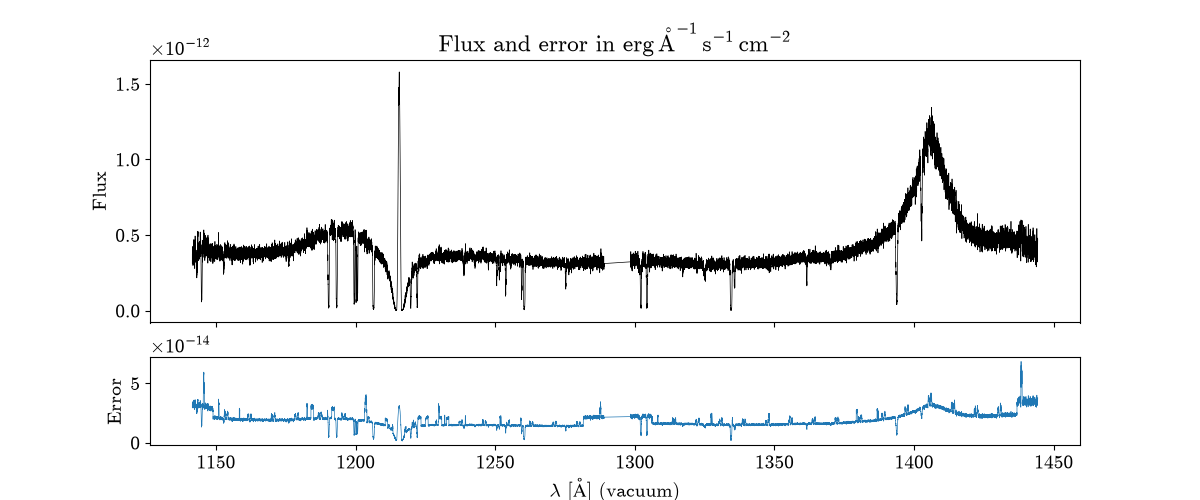

In [48]:
from spectral_diag.plots import plot_raw_spectrum

# lbgl31020, the visit with the highest S/N
spectrum = cos_spectra[1]

fig, axes = plot_raw_spectrum(spectrum)
plt.show()

### 1.2 The pixel grid

Unlike SDSS, COS pixels are uniform in wavelength, about 0.01 Å each. In velocity they go from ~2.6 km/s at the blue end to ~2.1 km/s at the red end, while the instrumental FWHM is ~16 km/s ($R \approx 19\,000$, against ~2000 for SDSS). A resolution element therefore spans 6–8 pixels, compared with ~2 in SDSS: the line profiles are well sampled, but the noise of neighbouring pixels is correlated (section 3.1).

The velocity arguments of the star tutorial (section 2.2 there) still hold for the physics: widths, resolution and redshift act in km/s. Only the grid is different, so code that needs the pixel width in km/s must not assume a single value; `find_features` takes the median over the spectrum.

> **Note:** the grid has a gap of ~9.5 Å between the two detector segments, around 1290 Å for this `cenwave`, plus the pixels cut in section 2.1.

In [49]:
from spectral_diag import constants

pixel_width = np.median(np.diff(spectrum.wave))
print(f"pixel width: {pixel_width:.4f} A")

# Pixels uniform in Angstrom: in velocity, c * d(lambda) / lambda, they
# shrink to the red
for wave in (spectrum.wave[0], spectrum.wave[-1]):
    pixel_kms = constants.C_KMS * pixel_width / wave
    pixels_per_resolution_element = spectrum.meta["fwhm_kms"] / pixel_kms
    print(
        f"at {wave:.0f} A: {pixel_kms:.2f} km/s, "
        f"{pixels_per_resolution_element:.1f} pixels per resolution element"
    )

# The widest step between neighbouring pixels is the gap between the segments
gap_start = np.argmax(np.diff(spectrum.wave))
gap_end = gap_start + 1
print(f"segment gap: {spectrum.wave[gap_start]:.1f}-{spectrum.wave[gap_end]:.1f} A")

pixel width: 0.0100 A
at 1142 A: 2.62 km/s, 6.1 pixels per resolution element
at 1444 A: 2.07 km/s, 7.7 pixels per resolution element
segment gap: 1289.0-1298.5 A


## 2. Continuum

We use the same `fit_continuum` (`spectral_diag/continuum.py`) as for the star: a cubic spline with knots every `knot_spacing` Å, weighted by 1/error, refitted while rejecting the pixels more than `clip_low` errors below it (see section 3 of the star tutorial). Two things change for the quasar: an emission line that is not part of the quasar must be removed first, and the knots must be much closer.

### 2.1 Removing the geocoronal $\mathrm{Ly}\alpha$

The narrow emission at 1215.67 Å is **geocoronal $\mathrm{Ly}\alpha$**: solar $\mathrm{Ly}\alpha$ scattered by the hydrogen of the Earth's exosphere, around HST. It is not light from the quasar. It fills the whole 2.5″ aperture of COS, so its profile is flat-topped with a FWHM of ~0.85 Å, instead of the ~0.065 Å of a point source, and it sits in the black core of the Galactic $\mathrm{Ly}\alpha$, where the quasar flux is close to zero.

Left in, it breaks the continuum fit. In the first iterations it pulls the spline up; every pixel around it is then below the fit and rejected, the fit never comes back down, and the continuum overshoots to ~3× the flux. `fit_continuum` can also reject pixels above the fit (`clip_high`, infinite by default), but the cleanest fix is to cut the pixels: the core is black, so no absorption line can be measured there anyway.

In [50]:
# Covers the whole saturated core of the Galactic Ly-alpha, wider than the
# ~0.85 A flat top of the geocoronal emission (Angstrom)
GEOCORONAL_LYA_WINDOW = (1214.0, 1217.0)

in_geocoronal_lya = (spectrum.wave > GEOCORONAL_LYA_WINDOW[0]) & (
    spectrum.wave < GEOCORONAL_LYA_WINDOW[1]
)
spectrum = spectrum.cut(~in_geocoronal_lya)

### 2.2 Choosing the knot spacing

The default `knot_spacing` of 250 Å, chosen for the Balmer lines of the star, gives a single spline interval over the ~300 Å of COS, which cannot follow the shape of the quasar continuum (the broad $\mathrm{Ly}\alpha$ emission at 1408 Å, the Galactic $\mathrm{Ly}\alpha$ trough). The spacing must instead be narrower than the structures of the continuum and wider than the lines. We compared three values:

| `knot_spacing` | Galactic $\mathrm{Ly}\alpha$ trough (1208–1226 Å) | metal lines (e.g. S II and Si II, 1248–1262 Å) |
|---|---|---|
| 5 Å | bridged at ~4× the flux at its bottom | flat under the lines |
| 2 Å | followed down to the bottom | flat under the lines |
| 1 Å | followed | dips into the saturated Si II 1260 |

With 5 Å the spline cannot bend into the ~5 Å wide trough: the pixels at its bottom are rejected, the intervals there keep fewer than 10 used pixels, the knots are removed (`_knots`) and the spline bridges the trough. With 1 Å the knots are as narrow as the saturated lines and the spline starts following them. We keep 2 Å: the metal lines (≲ 1 Å) are narrower than that, the trough is wider.

**Caveat.** With 2 Å the damped Galactic $\mathrm{Ly}\alpha$ becomes part of the "continuum". That is what we want for detecting the metal lines on top of it, but its column density N(HI) cannot be measured against this continuum.

converged after 8 iterations
27746 of 29065 pixels used


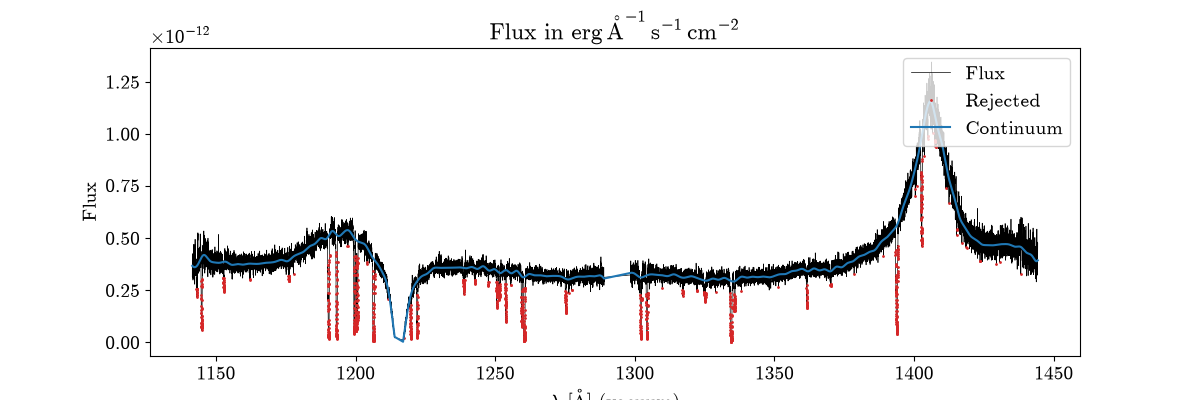

In [51]:
from spectral_diag.continuum import ContinuumSettings, fit_continuum
from spectral_diag.plots import plot_continuum

# Narrower than the Galactic Ly-alpha trough, wider than the metal lines
DETECTION_KNOT_SPACING = 2.0
# Margin over the default limit of 20 iterations
DETECTION_MAX_ITER = 50

detection_settings = ContinuumSettings(
    knot_spacing=DETECTION_KNOT_SPACING,
    max_iter=DETECTION_MAX_ITER,
    clip_low=4
)
fit = fit_continuum(spectrum, detection_settings)
print(f"{fit.status} after {fit.n_iter} iterations")
print(f"{fit.used.sum()} of {fit.used.size} pixels used")

fig, ax = plot_continuum(spectrum, fit)
plt.show()

### 2.3 Normalising

`normalise` divides the flux and the error by the continuum, as in section 3.3 of the star tutorial.

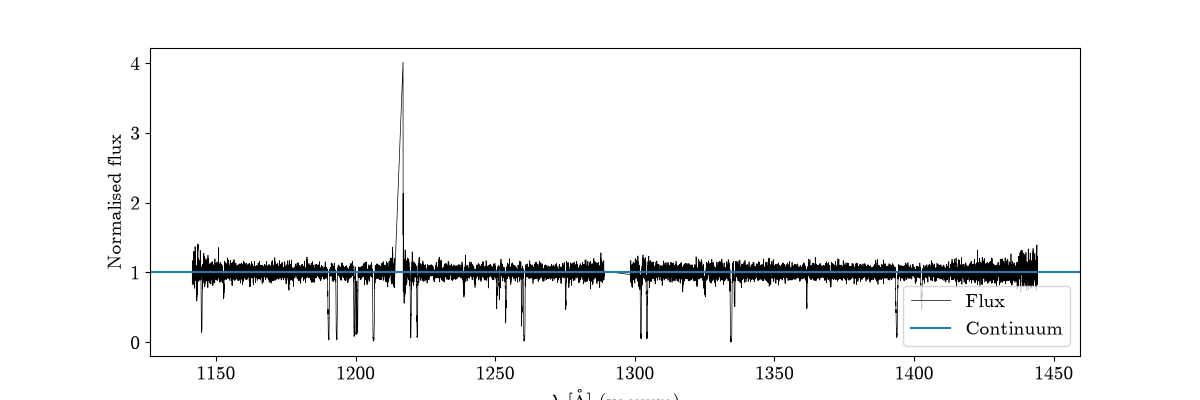

In [52]:
from spectral_diag.continuum import normalise
from spectral_diag.plots import plot_normalised

normalised_spectrum = normalise(spectrum, fit.continuum)

fig, ax = plot_normalised(normalised_spectrum)
plt.show()

The straight segments in the normalised spectrum are gaps of the pixel grid, not data: the segment gap (1289–1298 Å) and the cut geocoronal $\mathrm{Ly}\alpha$ (1214–1217 Å). Right after the cut, the normalised flux reaches ~3: there the continuum follows the bottom of the Galactic trough and is close to zero, so a pixel only $2\sigma$ above it gives a large ratio. Its error is just as large, so it does not affect the detection.

As for the star, `find_features` reads the continuum from `spectrum.continuum`, so we store the fit there, with its error in `spectrum.continuum_error`.

In [53]:
spectrum.continuum = fit.continuum
# Propagated into the EW errors (ew_err) of the features
spectrum.continuum_error = fit.error

## 3. Detecting the features

`find_features` (`spectral_diag/detect`) finds the significant dips without any line list, exactly as for the star (section 4 of the star tutorial, where the columns of the output table are described): it filters $1 - F_\mathrm{norm}$ with a Gaussian of the instrumental width and keeps the runs of pixels where the significance exceeds `threshold` (in $\sigma$).

### 3.1 The threshold

The $4\sigma$ of the star gives ~200 features here, most of them spurious, for two reasons.

**Correlated noise.** The matched filter assumes that the noise of each pixel is independent. In COS a resolution element spans 6–8 pixels, and the x1dsum resamples and co-adds the exposures, so the noise of neighbouring pixels is correlated (correlation coefficient ~0.2 up to 3–5 pixels apart). The significance then scatters by $\sim 2\sigma$ instead of $1\sigma$. To measure where pure noise ends, we search for *emission* (`sign=+1`): this spectrum has no narrow emission lines, so every emission "feature" is noise. The strongest one reaches $8.2\sigma$.

**Detector artefacts.** Between $\sim 8$ and $\sim 15\sigma$ there are still dips that are not noise, mostly at the red end of segment A (1400–1435 Å). They do not appear at the same wavelength in the visits with another `cenwave` (section 1), so they are on the detector, not in the sky: shadows of the grid wires and flat-field residuals. The strongest reaches $14.0\sigma$ (1404.9 Å).

We set the threshold just above it, at $15\sigma$. The price is that real weak lines between $8$ and $15\sigma$ are lost (e.g. Ni II 1370, C I 1277), while 15 rather than 16 keeps N V 1242.8 ($15.4\sigma$), the partner of N V 1238.8. Keeping them all would need a threshold of ~8 plus a check that each feature appears in another visit.

In [56]:
from spectral_diag.detect import find_features

# Just above the strongest detector artefact (14.0 sigma); pure noise reaches
# 8.2 sigma because the noise of neighbouring COS pixels is correlated
THRESHOLD = 16

features = find_features(spectrum, threshold=THRESHOLD)

print(f"{len(features)} features")
features.pprint_all()

27 features
  wave   wave_err wave_min wave_max depth   ew  ew_err   snr  
-------- -------- -------- -------- ----- ----- ------ -------
1144.890    0.003 1144.587 1145.274 0.859 0.310  0.006  55.206
1152.767    0.006 1152.319 1152.997 0.378 0.105  0.005  21.445
1176.072    0.008 1175.817 1176.275 0.253 0.060  0.004  17.162
1190.359    0.003 1189.848 1190.765 0.968 0.485  0.004 137.746
1193.242    0.004 1192.807 1193.605 0.966 0.467  0.003 175.866
1199.515    0.003 1199.155 1199.803 0.917 0.328  0.003 119.641
1200.200    0.004 1199.902 1200.431 0.893 0.301  0.002 136.229
1200.675    0.003 1200.441 1200.989 0.869 0.266  0.002 110.666
1206.441    0.006 1205.931 1207.008 0.984 0.617  0.003 177.017
1219.768    0.002 1219.334 1220.082 0.935 0.336  0.004  76.113
1222.085    0.003 1221.746 1222.493 0.929 0.328  0.005  71.856
1238.783    0.006 1238.417 1239.175 0.353 0.121  0.004  29.535
1250.560    0.005 1250.226 1250.844 0.522 0.124  0.004  34.762
1251.490    0.004 1251.212 1251.721 0.393 0

### 3.2 The windows

`plot_features` (`spectral_diag/plots.py`) draws the normalised spectrum with the window of each feature shaded and its centre marked. With `%matplotlib widget` the plot can be zoomed with the toolbar.

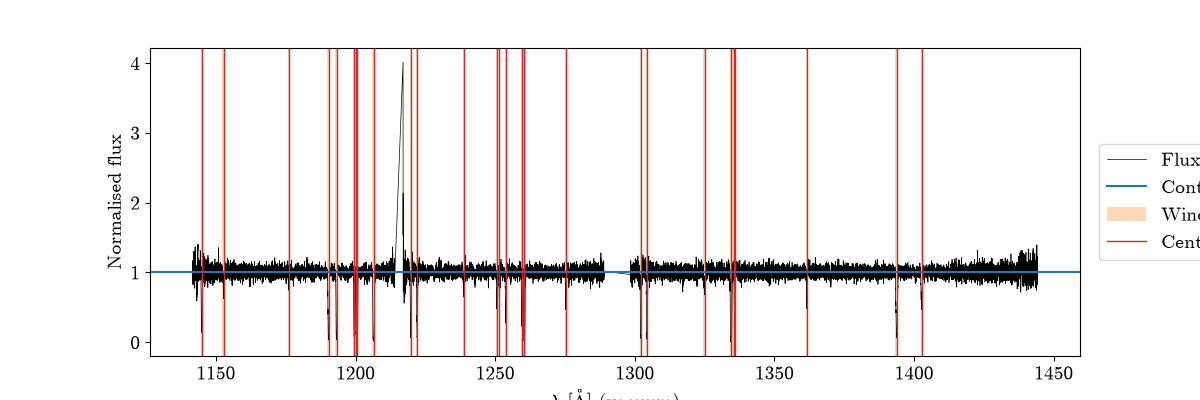

In [57]:
from spectral_diag.plots import plot_features

fig, ax = plot_features(normalised_spectrum, features)
plt.show()

## 4. Next steps

The features are not identified yet: `identify` (`spectral_diag/detect`) will slide the "comb" of each species over them. Matching each feature to the nearest line of `line_list` already suggests what to expect:

- about two thirds of the 31 features are Milky Way lines at $v \approx -10$ km/s: Fe II, Si II, N I, Si III, N V, S II, O I, C II and Si IV;
- 1219.8 and 1222.1 Å are $\mathrm{Ly}\alpha$ absorbers in front of the Virgo cluster ($cz \approx 1000$ and $1600$ km/s), and some others between 1216 and 1408 Å are probably $\mathrm{Ly}\alpha$ of the forest;
- a few belong to species not yet in `data/line_lists/` (P II 1152.8, Ni II 1317.2) or to excited levels excluded by default (C II* 1335.7, `e_low_max`).

After the identification come the local continuum and the equivalent width of each line, and the curve of growth of the species with several lines, e.g. the S II triplet (1250, 1253, 1259 Å) and Si II (1190, 1193, 1260, 1304 Å).